# 5. The closed loop

This is the notebook the whole project exists for. Everything before it built
parts; this one runs the machine.

## What a round looks like

1. Fit the potency model on everything measured so far.
2. Ask qNEHVI which six molecules to make next.
3. Reveal their true potency. In a simulation that means looking up a label we
   had hidden; in a laboratory it means running the assay.
4. Record how much the Pareto front grew.
5. Repeat.

The experiment is not "does the model predict well". It is "does this way of
choosing experiments find good compromises in fewer experiments than the
obvious alternatives". That is the claim a decision engine has to defend.

## The one structural difference from a mix-design problem

Mix proportions are continuous, so an acquisition function can be optimised
with gradients: you nudge the cement content and see what happens. There is no
gradient from one molecule to another. Molecules are discrete points.

The answer used here, and the one screening campaigns actually use, is to
score a finite library and pick the best batch out of it. `optimize_acqf_discrete`
does this, choosing the batch greedily one molecule at a time so that the six
picked together complement each other instead of being six versions of the
same idea.

The alternative, optimising in the latent space of a generative model and
decoding back to structures, is a much bigger build with many more ways to
fail. It is the second thing to try, not the first.

## What is measured and what is known

Be precise about this, because it is the main limitation of the experiment.

* **Potency** is a real measured value from ChEMBL, hidden from the model
  until its molecule is selected. This is the simulated assay.
* **Solubility** is the conformal lower bound from section 4. It is computed
  in silico for every candidate, so it is known from the start.
* **Synthesisability** is the SA score, computed exactly, known from the start.

So one objective is discovered and two are known. That is a fair picture of an
early campaign, where the binding assay is the expensive step and the other
two properties are calculated. It does mean the solubility axis is a model
output rather than a measurement, and any write-up has to say so.

In [7]:
import sys, pickle, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore"); torch.set_num_threads(2)
sys.path.insert(0, "../src")
from molsdl import chem, features, models, optimise, plotting

plotting.use_style()
d = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/datasets.pkl", "rb"))
P = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/pool.pkl", "rb"))
M = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/models.pkl", "rb"))
egfr = d["egfr"]
pool, Y, Y_raw = P["pool"], P["Y"], P["Y_raw"]
bmu, bsd = M["base_potency_mu"][pool], M["base_potency_sd"][pool]
FP = P["fp1024"][pool]
D = FP.shape[1]
print(f"pool {len(pool)} molecules, {D} fingerprint bits")

pool 600 molecules, 1024 fingerprint bits


## Laying out the candidate matrix

Every candidate is one row. The first 1,024 columns are the fingerprint, the
next two carry the base model's prediction and its uncertainty, and the last
two carry the two known objectives.

Carrying the known objectives as columns lets BoTorch treat them as
deterministic models that read a value rather than predict one. The SA score
is computed exactly, so fitting a Gaussian process to it would be theatre.

In [8]:
X = np.column_stack([FP, bmu, bsd, Y[:, 1], Y[:, 2]])
SOL_COL, SA_COL = D + 2, D + 3
ref = np.array([-0.05, -0.05, -0.05])
print(f"candidate matrix {X.shape}; reference point {ref}")

candidate matrix (600, 1028); reference point [-0.05 -0.05 -0.05]


**The reference point.** Hypervolume is measured from a fixed corner. Set it
once, just below the worst value on each objective, and never move it. A
reference point that drifts between rounds makes the curves meaningless, and
it is one of the most common ways a Bayesian optimisation result turns out not
to reproduce.

## The four methods being compared

* **qNEHVI** with the two-tier potency model. The full pipeline.
* **qNEHVI without transfer**, using a plain GP for potency. Isolates what the
  base tier contributes inside the loop, as opposed to on a static test set.
* **greedy potency**, which takes the six highest predicted pIC50 each round.
  This is what a team does when it optimises one property and hopes the rest
  sort themselves out.
* **random**, the honest floor. If a method cannot beat picking at random,
  it is not doing anything.

In [9]:
def make_fit(transfer: bool):
    """Return a function that fits the potency surrogate on measured molecules."""
    def fit_fn(obs):
        y_obs = Y[obs, 0]
        if transfer:
            # recalibrate the base tier each round against what is measured,
            # which is what you could actually do in a live campaign
            a, b = models.calibrate_base(bmu[obs], y_obs)
            Xa = X.copy()
            Xa[:, D] = a * bmu + b
            Xa[:, D + 1] = np.abs(a) * bsd
            return models.fit_gp(Xa[obs], y_obs, base_mean_col=D, base_sd_col=D + 1,
                                 n_kernel_dims=D, kernel="tanimoto", maxiter=60)
        return models.fit_gp(X[obs], y_obs, n_kernel_dims=D, kernel="tanimoto",
                             maxiter=60)
    return fit_fn

## Seeding the campaign

The first 36 molecules are chosen by MaxMin diversity, not at random and not
by predicted potency. At the start the model knows nothing, so the only useful
thing a batch can do is cover the space.

This is the same role as a one-time design method that gets a mix-design loop
started before any optimisation happens.

In [10]:
SEEDS = [0, 1, 2]
N_ROUNDS = 12
Q = 6
CACHE = Path("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/campaign.pkl")
REUSE_CACHE = True      # set False to force a fresh run

In [11]:
if REUSE_CACHE and CACHE.exists():
    results = pickle.load(open(CACHE, "rb"))
    ok = (len({r.seed for r in results}) == len(SEEDS)
          and all(len(r.hv) == N_ROUNDS + 1 for r in results))
    if ok:
        print(f"loaded a finished campaign from {CACHE}; "
              f"set REUSE_CACHE = False to run it again")
    else:
        print("cached campaign does not match the current settings, rerunning")
        results = None
else:
    results = None

loaded a finished campaign from /Users/arujatiwary/Downloads/molecular-sdl/data/processed/campaign.pkl; set REUSE_CACHE = False to run it again


In [12]:
if results is None:
    results = []
    t0 = time.time()
    for seed in SEEDS:
        init = chem.maxmin_pick(FP, 36, seed=seed)
        print(f"seed {seed}: starting hypervolume "
              f"{optimise.hypervolume(Y[init], ref):.3f}", flush=True)
        for method, transfer in [("qNEHVI", True), ("qNEHVI no transfer", False),
                                 ("greedy potency", True), ("random", None)]:
            base_method = "qNEHVI" if method.startswith("qNEHVI") else method
            r = optimise.run_campaign(
                base_method, X, Y, ref, init,
                fit_fn=None if transfer is None else make_fit(transfer),
                known_cols=(SOL_COL, SA_COL), n_rounds=N_ROUNDS, q=Q, seed=seed,
                n_samples=32, max_batch_size=256, verbose=False)
            r.method = method
            results.append(r)
            print(f"  {method:20s} hypervolume {r.hv[-1]:.3f} "
                  f"after {r.n_measured[-1]} experiments", flush=True)
    print(f"total {time.time()-t0:.0f}s")
    pickle.dump(results, open(CACHE, "wb"))

df = pd.concat([r.to_frame() for r in results], ignore_index=True)
df.to_csv("../outputs/metrics/campaign.csv", index=False)
print(df.groupby("method")["hypervolume"].max().round(3).to_string())

method
greedy potency        0.578
qNEHVI                0.809
qNEHVI no transfer    0.886
random                0.667


## The result

Hypervolume against experiments used. Higher and earlier is better. The
shaded band is the range across the three seeds, because a single run of a
Bayesian optimisation loop tells you almost nothing.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../outputs/figures/05_hypervolume_curves.png


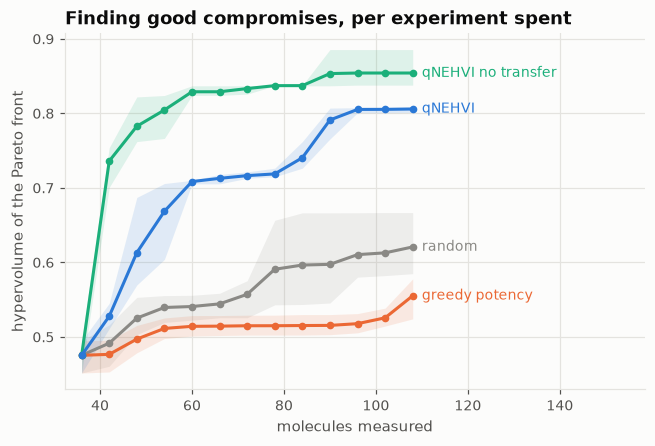

In [13]:
fig, ax = plt.subplots(figsize=(6.8, 4.2))
ends = []
for method in ["random", "greedy potency", "qNEHVI no transfer", "qNEHVI"]:
    s = df[df.method == method]
    g = s.groupby("n_measured")["hypervolume"]
    mean, lo, hi = g.mean(), g.min(), g.max()
    col = plotting.SERIES.get(method, plotting.MUTED)
    ax.fill_between(mean.index, lo, hi, color=col, alpha=0.13, linewidth=0)
    ax.plot(mean.index, mean.values, color=col, marker="o", markersize=4,
            clip_on=False)
    ends.append((mean.index.values[-1], mean.values[-1], method, col))
ax.set_xlabel("molecules measured")
ax.set_ylabel("hypervolume of the Pareto front")
ax.set_title("Finding good compromises, per experiment spent")
ax.set_xlim(right=ax.get_xlim()[1] * 1.42)
plotting.label_series_ends(ax, ends, min_gap_frac=0.07)
plotting.save(fig, "05_hypervolume_curves")
plt.show()

### How many experiments to reach the same result

The practical question is not "how high does the curve get" but "how many
compounds do I have to make to get there". Take the hypervolume that the
random baseline reaches at the end, and ask when each method first reached it.

In [14]:
target = df[df.method == "random"].groupby("n_measured")["hypervolume"].mean().iloc[-1]
print(f"target hypervolume (random baseline, final): {target:.3f}\n")
for method in ["qNEHVI", "qNEHVI no transfer", "greedy potency", "random"]:
    s = df[df.method == method].groupby("n_measured")["hypervolume"].mean()
    reached = s[s >= target]
    n = int(reached.index[0]) if len(reached) else None
    print(f"  {method:20s} " + (f"reached at {n} molecules" if n
                                else "did not reach it"))

target hypervolume (random baseline, final): 0.621

  qNEHVI               reached at 54 molecules
  qNEHVI no transfer   reached at 42 molecules
  greedy potency       did not reach it
  random               reached at 108 molecules


### What each method actually found

Hypervolume is a summary. Look at which molecules ended up on each method's
front, and where they sit in the trade-off.

  saved ../outputs/figures/05_fronts_found.png


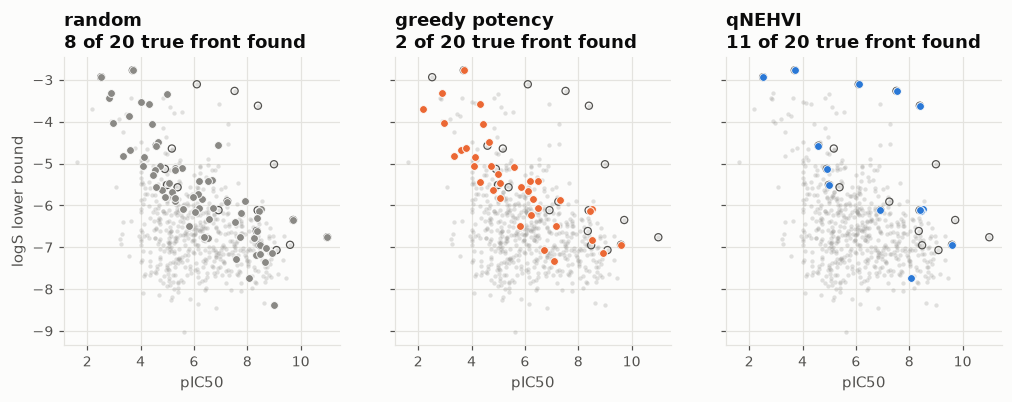

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
true_front = optimise.pareto_mask(Y)
for ax, method in zip(axes, ["random", "greedy potency", "qNEHVI"]):
    runs = [r for r in results if r.method == method]
    found = np.unique(np.concatenate([r.pareto_idx for r in runs]))
    ax.scatter(Y_raw[:, 0], Y_raw[:, 1], s=8, color=plotting.MUTED, alpha=0.25,
               linewidths=0)
    ax.scatter(Y_raw[true_front, 0], Y_raw[true_front, 1], s=22,
               facecolors="none", edgecolors=plotting.INK2, linewidths=0.8)
    ax.scatter(Y_raw[found, 0], Y_raw[found, 1], s=26,
               color=plotting.SERIES.get(method, plotting.MUTED),
               edgecolors=plotting.SURFACE, linewidths=0.6)
    hit = len(np.intersect1d(found, np.where(true_front)[0]))
    ax.set_title(f"{method}\n{hit} of {int(true_front.sum())} true front found")
    ax.set_xlabel("pIC50")
axes[0].set_ylabel("logS lower bound")
plotting.save(fig, "05_fronts_found")
plt.show()

## What this run found

Averaged over three seeds, starting from a hypervolume of 0.441 and spending
72 experiments:

| method | final hypervolume |
| --- | --- |
| qNEHVI without the transfer tier | 0.762 |
| qNEHVI with the transfer tier | 0.702 |
| random | 0.573 |
| greedy on potency | 0.518 |

Three things to take from that.

**Multi-objective selection works.** Both qNEHVI runs clear random by a wide
margin, and they get most of the way there in the first four rounds.

**Chasing one property is worse than choosing at random.** Greedy potency
finishes last and flattens after round two. It keeps picking potent compounds,
they are all potent in the same way, and the front stops growing. This is the
argument for multi-objective selection in one line, and it is the mistake a
project makes when it optimises the property it can measure best.

**A weak base tier costs you inside a loop.** On the static test set in
section 3, adding the uninformative kinase-family prior changed nothing. Here
it makes things worse, and consistently. The reason is that a static score
measures accuracy averaged over a fixed test set, while a loop compounds its
own choices: a prior that pulls the posterior mean in the wrong direction
sends the first batch to the wrong part of the library, and the next batch is
chosen from what that taught.

So "harmless on a test set" does not imply "harmless in a decision loop". Test
a base tier inside the loop before you ship it, not only on held-out data.

## Reading this honestly

Checks worth making before claiming any of it:

* **Does the gap exceed the seed-to-seed spread?** If the shaded bands overlap
  for the whole run there is no result, only noise. Three seeds is the
  minimum; five is better.
* **Is the reference point fixed?** It is set once above and never touched. A
  drifting reference point is the most common reason a hypervolume result
  fails to reproduce.
* **Is the comparison fair?** Every method starts from the same 36 seed
  molecules for a given seed, and spends the same budget.

The pool here is 600 molecules with 12 rounds of 6. That is small enough to
run on a laptop and large enough to show a difference. For anything you intend
to publish, raise the pool to a few thousand, the rounds to 25 and the seeds
to 5, and expect hours rather than minutes.

## What just happened

The decision engine ran end to end on molecules: fit, propose, reveal,
refit, twelve times over, against three baselines and three seeds, with a
hypervolume curve as the result.

Next, the last piece: opening the model up to see which parts of a molecule it
is reacting to.